<a href="https://colab.research.google.com/github/mloulaps-rgb/---/blob/main/HCI_%D0%9B%D0%A08_%D0%92%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BD%D1%96_%D0%BF%D0%BE%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_%D1%81%D0%BB%D1%96%D0%B2_CBOW_%D0%92%D0%B5%D0%BB%D0%B8%D1%87%D0%BA%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Крок 1. Імпорт бібліотек та завантаження корпусу
import os, re, pickle
import numpy as np
import nltk
from nltk.tokenize import word_tokenize
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import ipywidgets as widgets
from IPython.display import display, clear_output
%config InlineBackend.figure_format = 'svg'

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

# Завантаження текстового корпусу (твори Шекспіра)
URL = ("https://raw.githubusercontent.com/amanchadha/"
       "coursera-natural-language-processing-specialization/master/"
       "2%20-%20Natural%20Language%20Processing%20with%20Probabilistic%20Models/"
       "Week%204/shakespeare.txt")
if not os.path.exists("my_corpus.txt"):
    os.system(f'wget -q "{URL}" -O my_corpus.txt')
print("Корпус завантажено, розмір:", os.path.getsize("my_corpus.txt"), "байт")


Корпус завантажено, розмір: 306996 байт


In [2]:
# Крок 2. Функції обробки тексту та підготовки даних
def tokenize(corpus):
    """Токенізація та очищення тексту."""
    data = re.sub(r'[,!?;-]+', '.', corpus)
    data = nltk.word_tokenize(data)
    data = [ch.lower() for ch in data if ch.isalpha() or ch == '.']
    return data

def get_dict(data):
    """Словники {слово:індекс} та {індекс:слово}."""
    words = sorted(list(set(data)))
    word2Ind, Ind2word = {}, {}
    for idx, word in enumerate(words):
        word2Ind[word] = idx
        Ind2word[idx] = word
    return word2Ind, Ind2word

def get_idx(words, word2Ind):
    return [word2Ind[word] for word in words]

def pack_idx_with_frequency(context_words, word2Ind):
    freq_dict = defaultdict(int)
    for word in context_words:
        freq_dict[word] += 1
    idxs = get_idx(context_words, word2Ind)
    return [(idxs[i], freq_dict[context_words[i]]) for i in range(len(idxs))]

def get_vectors(data, word2Ind, V, C):
    """Генерує пари (усереднений контекст, one-hot центрального слова)."""
    i = C
    while True:
        y = np.zeros(V); x = np.zeros(V)
        center_word = data[i]
        y[word2Ind[center_word]] = 1
        context_words = data[(i - C):i] + data[(i + 1):(i + C + 1)]
        num_ctx_words = len(context_words)
        for idx, freq in pack_idx_with_frequency(context_words, word2Ind):
            x[idx] = freq / num_ctx_words
        yield x, y
        i += 1
        if i >= len(data) - C:
            i = C

def get_batches(data, word2Ind, V, C, batch_size):
    """Формує батчі для навчання."""
    batch_x, batch_y = [], []
    for x, y in get_vectors(data, word2Ind, V, C):
        if len(batch_x) < batch_size:
            batch_x.append(x); batch_y.append(y)
        else:
            yield np.array(batch_x).T, np.array(batch_y).T
            batch_x, batch_y = [], []

print("Функції обробки тексту визначено.")


Функції обробки тексту визначено.


In [3]:
# Крок 3. Імплементація моделі CBOW
def initialize_model(N, V, random_seed=1):
    """Ініціалізація ваг W1, W2 та зміщень b1, b2."""
    np.random.seed(random_seed)
    W1 = np.random.rand(N, V)
    W2 = np.random.rand(V, N)
    b1 = np.random.rand(N, 1)
    b2 = np.random.rand(V, 1)
    return W1, W2, b1, b2

def softmax(z):
    """Softmax по стовпцях."""
    e_z = np.exp(z)
    return e_z / np.sum(e_z, axis=0)

def forward_prop(x, W1, W2, b1, b2):
    """Пряме поширення: h = ReLU(W1x+b1), z = W2h+b2."""
    h = np.dot(W1, x) + b1
    h = np.maximum(0, h)
    z = np.dot(W2, h) + b2
    return z, h

def compute_cost(y, yhat, batch_size):
    """Крос-ентропійна функція втрат."""
    logprobs = np.multiply(np.log(yhat), y)
    cost = -1 / batch_size * np.sum(logprobs)
    return np.squeeze(cost)

def back_prop(x, yhat, y, h, W1, W2, b1, b2, batch_size):
    """Зворотне поширення помилки."""
    z1 = np.dot(W1, x) + b1
    l1 = np.dot(W2.T, yhat - y)
    l1[z1 < 0] = 0
    grad_W1 = np.dot(l1, x.T) / batch_size
    grad_W2 = np.dot(yhat - y, h.T) / batch_size
    grad_b1 = np.sum(l1, axis=1, keepdims=True) / batch_size
    grad_b2 = np.sum(yhat - y, axis=1, keepdims=True) / batch_size
    return grad_W1, grad_W2, grad_b1, grad_b2

def gradient_descent(data, word2Ind, N, V, num_iters, alpha=0.03, batch_size=128, C=2, verbose=True):
    """Навчання CBOW міні-пакетним градієнтним спуском."""
    W1, W2, b1, b2 = initialize_model(N, V)
    iters = 0
    for x, y in get_batches(data, word2Ind, V, C, batch_size):
        z, h = forward_prop(x, W1, W2, b1, b2)
        yhat = softmax(z)
        cost = compute_cost(y, yhat, batch_size)
        if verbose and ((iters + 1) % 50 == 0):
            print(f"Ітерація: {iters + 1}, витрати: {cost:.6f}")
        grad_W1, grad_W2, grad_b1, grad_b2 = back_prop(x, yhat, y, h, W1, W2, b1, b2, batch_size)
        W1 -= alpha * grad_W1
        W2 -= alpha * grad_W2
        b1 -= alpha * grad_b1
        b2 -= alpha * grad_b2
        iters += 1
        if iters == num_iters:
            break
        if iters % 100 == 0:
            alpha *= 0.66
    return W1, W2, b1, b2

print("Модель CBOW визначено.")


Модель CBOW визначено.


In [4]:
# Крок 4. Метод головних компонент (PCA) для візуалізації
def compute_pca(X, n_components=2):
    """PCA для зменшення розмірності векторних подань."""
    X_centered = X - np.mean(X, axis=0)
    cov_matrix = np.cov(X_centered, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
    idx = np.argsort(eigenvalues)[::-1]
    eigenvectors = eigenvectors[:, idx][:, :n_components]
    return np.dot(X_centered, eigenvectors)

print("Функцію PCA визначено.")


Функцію PCA визначено.


In [5]:
# Крок 5. Збереження та завантаження векторних подань
def save_embeddings(W1, W2, word2Ind, Ind2word, filepath):
    """Зберігає векторні подання у файл (pickle)."""
    word_embeddings = (W1.T + W2) / 2.0
    embeddings_dict = {word: word_embeddings[idx, :] for word, idx in word2Ind.items()}
    with open(filepath, "wb") as f:
        pickle.dump({"embeddings": embeddings_dict,
                     "word2Ind": word2Ind, "Ind2word": Ind2word}, f)
    print(f"Векторні подання збережено у файл: {filepath}")

def load_embeddings(filepath):
    """Завантажує векторні подання з файлу."""
    with open(filepath, "rb") as f:
        data = pickle.load(f)
    print(f"Векторні подання завантажено з файлу: {filepath}")
    return data["embeddings"], data["word2Ind"], data["Ind2word"]

print("Функції збереження/завантаження визначено.")


Функції збереження/завантаження визначено.


In [6]:
# Крок 6. Підготовка корпусу та навчання моделі CBOW
with open("my_corpus.txt", "r") as f:
    corpus = f.read()

words = tokenize(corpus)
word2Ind, Ind2word = get_dict(words)
V = len(word2Ind)
print(f"Кількість токенів: {len(words)}")
print(f"Розмір словника: {V}")
print("Приклад токенів:", words[:12])
word_freq = Counter(words)
print("Найчастіші слова:", word_freq.most_common(8))

# Параметри моделі
C = 2            # половина вікна контексту
N = 50           # розмірність векторних подань
num_iters = 500  # кількість ітерацій
alpha = 0.03     # швидкість навчання
batch_size = 128

print("\nПочаток навчання моделі CBOW...")
W1, W2, b1, b2 = gradient_descent(words, word2Ind, N, V, num_iters, alpha, batch_size, C)
print("Навчання завершено!")

# Остаточні векторні подання та збереження
word_embeddings = (W1.T + W2) / 2.0
save_embeddings(W1, W2, word2Ind, Ind2word, "word_embeddings.pkl")
print("Форма матриці векторних подань:", word_embeddings.shape)


Кількість токенів: 61000
Розмір словника: 5784
Приклад токенів: ['o', 'for', 'a', 'muse', 'of', 'fire', '.', 'that', 'would', 'ascend', 'the', 'brightest']
Найчастіші слова: [('.', 9630), ('the', 1521), ('and', 1394), ('i', 1259), ('to', 1159), ('of', 1093), ('my', 857), ('that', 781)]

Початок навчання моделі CBOW...
Ітерація: 50, витрати: 9.599632
Ітерація: 100, витрати: 8.624066
Ітерація: 150, витрати: 8.580205
Ітерація: 200, витрати: 8.737647
Ітерація: 250, витрати: 7.837057
Ітерація: 300, витрати: 7.634260
Ітерація: 350, витрати: 7.045091
Ітерація: 400, витрати: 7.172036
Ітерація: 450, витрати: 8.338280
Ітерація: 500, витрати: 7.587116
Навчання завершено!
Векторні подання збережено у файл: word_embeddings.pkl
Форма матриці векторних подань: (5784, 50)


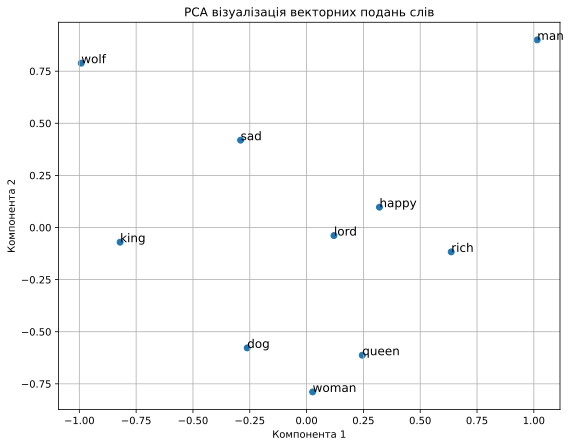

Найближчі слова до 'king':
  king: 1.0000
  happier: 0.9368
  vileness: 0.9322
  survey: 0.9287
  smells: 0.9273
  gladly: 0.9266

king - man + woman = ?
  king: 0.8878
  woman: 0.8743
  babes: 0.8576
  intent: 0.8456
  subject: 0.8451


In [7]:
# Крок 7. Дослідження та візуалізація векторних подань (PCA)
words_to_visualize = ['king', 'queen', 'lord', 'man', 'woman', 'dog', 'wolf', 'rich', 'happy', 'sad']
idx = [word2Ind[w] for w in words_to_visualize]
X = word_embeddings[idx, :]
result = compute_pca(X, 2)

plt.figure(figsize=(9, 7))
plt.scatter(result[:, 0], result[:, 1])
for i, word in enumerate(words_to_visualize):
    plt.annotate(word, xy=(result[i, 0], result[i, 1]), fontsize=12)
plt.title("PCA візуалізація векторних подань слів")
plt.xlabel("Компонента 1"); plt.ylabel("Компонента 2")
plt.grid(True)
plt.show()

# Векторна арифметика
embeddings_dict = {word: word_embeddings[word2Ind[word]] for word in word2Ind}

def find_closest_words(embedding, embeddings_dict, top_n=5):
    sims = [(w, np.dot(embedding, v) / (np.linalg.norm(embedding) * np.linalg.norm(v)))
            for w, v in embeddings_dict.items()]
    sims.sort(key=lambda x: x[1], reverse=True)
    return sims[:top_n]

print("Найближчі слова до 'king':")
for w, s in find_closest_words(embeddings_dict['king'], embeddings_dict, 6):
    print(f"  {w}: {s:.4f}")

print("\nking - man + woman = ?")
res_vec = embeddings_dict['king'] - embeddings_dict['man'] + embeddings_dict['woman']
for w, s in find_closest_words(res_vec, embeddings_dict, 5):
    print(f"  {w}: {s:.4f}")


In [8]:
# Крок 8. Інтерфейс користувача (ipywidgets)
def create_ui(embeddings_dict, word2Ind):
    word_input = widgets.Text(value="", placeholder="Введіть слово...", description="Слово:")
    find_similar_button = widgets.Button(description="Знайти подібні слова", button_style="primary")
    top_n_slider = widgets.IntSlider(value=5, min=1, max=20, step=1, description="Кількість слів:",
                                     continuous_update=False)
    arithmetic_input = widgets.Text(value="", placeholder="Приклад: king - man + woman",
                                    description="Арифметика:", layout=widgets.Layout(width="500px"))
    arithmetic_button = widgets.Button(description="Обчислити", button_style="success")
    output_area = widgets.Output()

    def cosine_similarity(a, b):
        return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

    def find_similar_words(word, top_n=5):
        if word not in embeddings_dict:
            return []
        wv = embeddings_dict[word]
        sims = [(ow, cosine_similarity(wv, ov)) for ow, ov in embeddings_dict.items() if ow != word]
        sims.sort(key=lambda x: x[1], reverse=True)
        return sims[:top_n]

    def word_arithmetic(pos, neg, top_n=5):
        if not all(w in embeddings_dict for w in pos + neg):
            return []
        rv = np.zeros_like(list(embeddings_dict.values())[0])
        for w in pos: rv += embeddings_dict[w]
        for w in neg: rv -= embeddings_dict[w]
        rv = rv / np.linalg.norm(rv)
        sims = [(w, cosine_similarity(rv, v)) for w, v in embeddings_dict.items() if w not in pos + neg]
        sims.sort(key=lambda x: x[1], reverse=True)
        return sims[:top_n]

    def on_find(b):
        word = word_input.value.strip().lower(); top_n = top_n_slider.value
        with output_area:
            clear_output()
            if not word:
                print("Будь ласка, введіть слово."); return
            if word not in embeddings_dict:
                print(f"Слово '{word}' не знайдено у словнику."); return
            print(f"Слова, подібні до '{word}':")
            for i, (w, s) in enumerate(find_similar_words(word, top_n), 1):
                print(f"{i}. {w} (схожість: {s:.4f})")

    def on_arith(b):
        expr = arithmetic_input.value.strip().lower(); top_n = top_n_slider.value
        with output_area:
            clear_output()
            if not expr:
                print("Введіть вираз для векторної арифметики."); return
            pos, neg = [], []
            parts = [p.strip() for p in expr.replace('-', '+-').split('+') if p.strip()]
            for part in parts:
                if part.startswith('-'):
                    w = part[1:].strip()
                    if w in embeddings_dict: neg.append(w)
                    else: print(f"Слово '{w}' не знайдено."); return
                else:
                    if part in embeddings_dict: pos.append(part)
                    else: print(f"Слово '{part}' не знайдено."); return
            res = word_arithmetic(pos, neg, top_n)
            label = ' + '.join(pos) + (' - ' + ' - '.join(neg) if neg else '')
            print(f"Результат для виразу '{label}':")
            for i, (w, s) in enumerate(res, 1):
                print(f"{i}. {w} (схожість: {s:.4f})")

    find_similar_button.on_click(on_find)
    arithmetic_button.on_click(on_arith)
    display(widgets.VBox([
        widgets.Label("Пошук подібних слів:"),
        widgets.HBox([word_input, find_similar_button]),
        top_n_slider,
        widgets.HTML("<hr>"),
        widgets.Label("Векторна арифметика:"),
        widgets.HBox([arithmetic_input, arithmetic_button]),
        widgets.HTML("<hr>"),
        output_area]))

create_ui(embeddings_dict, word2Ind)
print("Інтерфейс створено. Введіть слово або вираз і натисніть кнопку.")


Інтерфейс створено. Введіть слово або вираз і натисніть кнопку.
